# Hierarchical and DBSCAN Clustering on the Wine Dataset

**Name:** Sandeep Reddy Polareddy  
**Course:** Advanced Big Data and Data Mining (MSCS-634-B01)  
**Lab Assignment:** Hierarchical and DBSCAN Clustering

## Objective
Apply Agglomerative Hierarchical Clustering and DBSCAN to the Wine dataset, visualize the resulting clusters, evaluate clustering quality, and compare the algorithms.

## Step 1: Data Preparation and Exploration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

# Load the Wine dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target

print("Dataset shape:", X.shape)
display(X.head())
print("\nDataset information:")
X.info()
print("\nDescriptive statistics:")
display(X.describe())

# Standardize features so variables with larger numeric scales do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce standardized data to two dimensions for visualization only
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance by first two principal components:",
      round(pca.explained_variance_ratio_.sum(), 4))

Dataset shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


Explained variance by first two principal components: 0.5541


## Step 2: Agglomerative Hierarchical Clustering

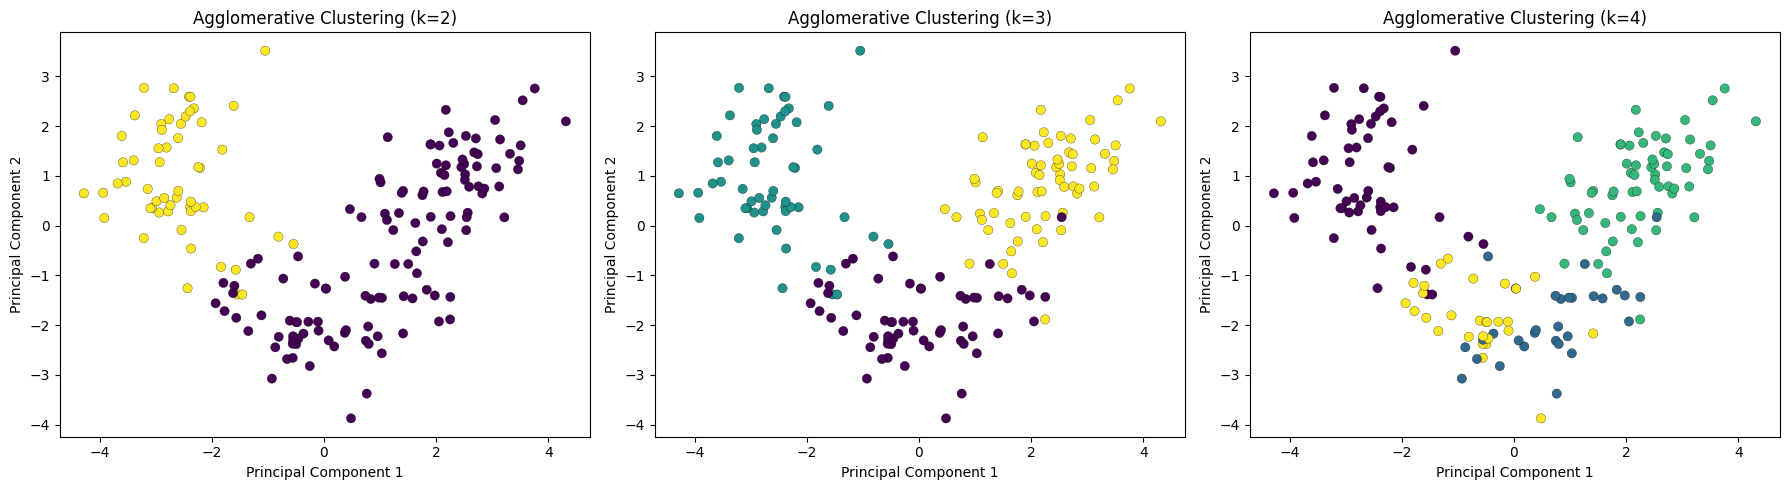

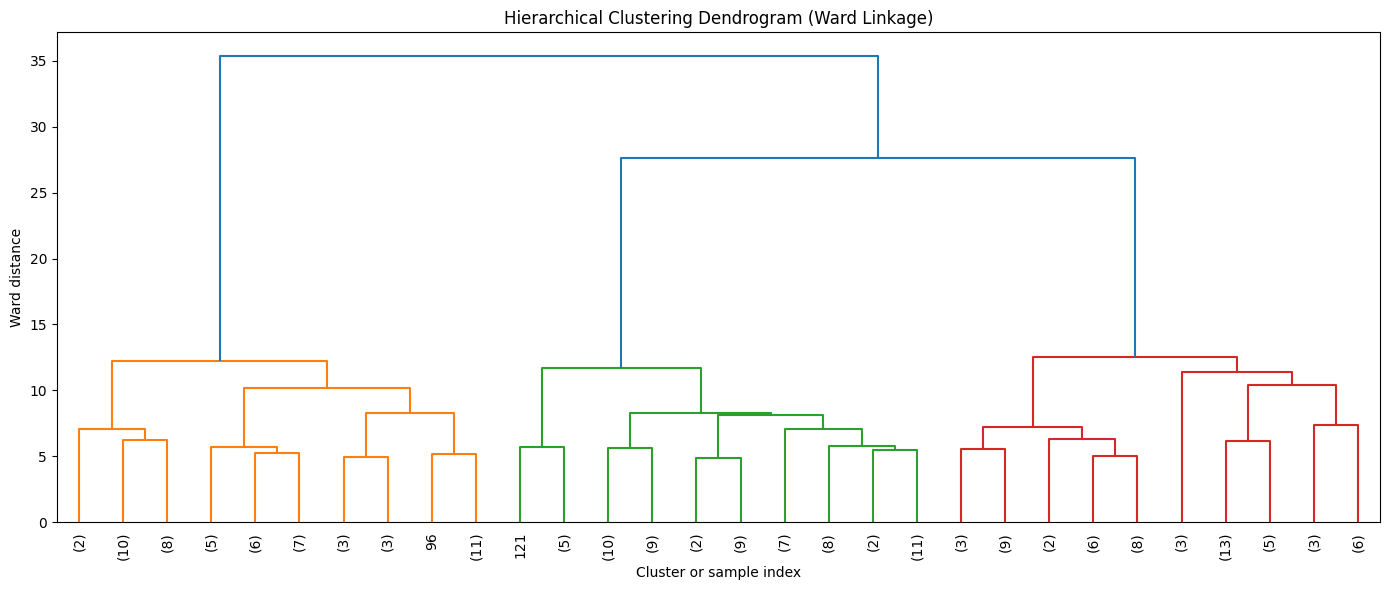

k=2: silhouette score = 0.2670
k=3: silhouette score = 0.2774
k=4: silhouette score = 0.2258


In [2]:
# Compare several cluster counts
hierarchical_results = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [2, 3, 4]):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    hierarchical_results[k] = labels

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=labels, cmap="viridis", s=45, edgecolor="k", linewidth=0.2
    )
    ax.set_title(f"Agglomerative Clustering (k={k})")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

# Dendrogram using Ward linkage
linkage_matrix = linkage(X_scaled, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30,
           show_leaf_counts=True, leaf_rotation=90)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster or sample index")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

# Silhouette scores for the tested hierarchical cluster counts
for k, labels in hierarchical_results.items():
    print(f"k={k}: silhouette score = {silhouette_score(X_scaled, labels):.4f}")

## Step 3: DBSCAN Clustering

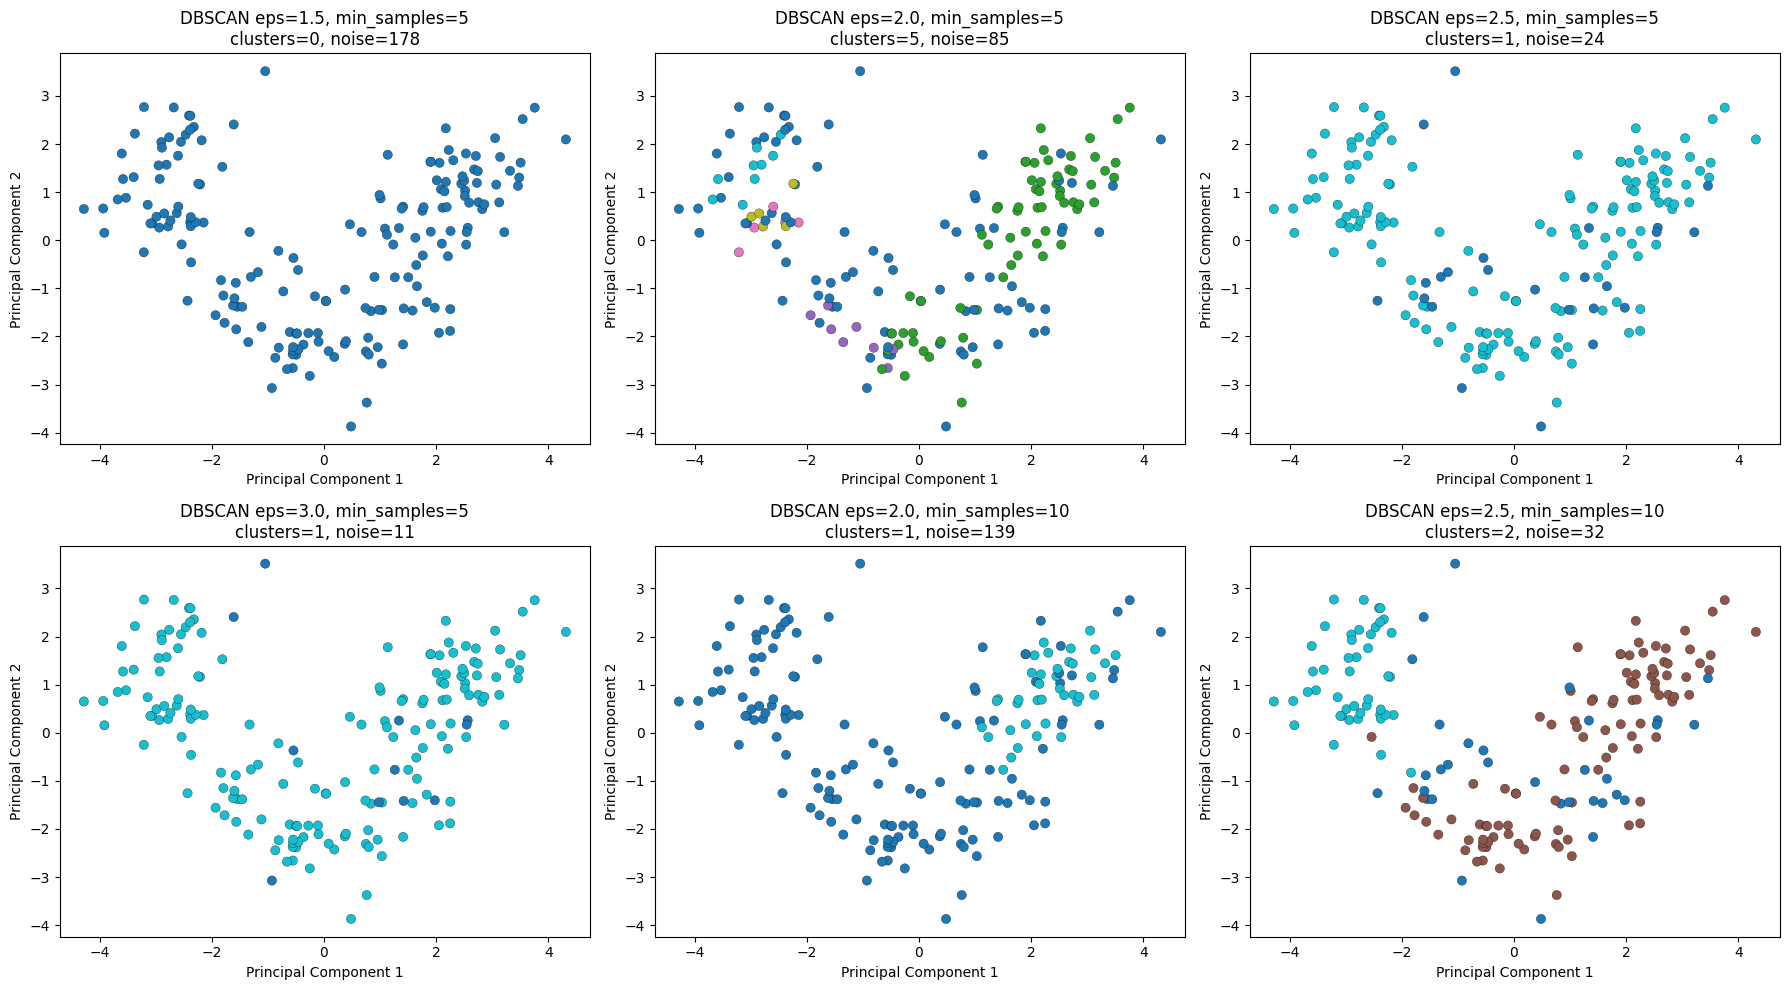

,eps,min_samples,clusters_found,noise_points,silhouette_non_noise,homogeneity,completeness
0,1.5,5,0,178,NaN,0.0000,1.0000
1,2.0,5,5,85,0.2405,0.3624,0.3247
2,2.5,5,1,24,NaN,0.0576,0.1581
3,3.0,5,1,11,NaN,0.0309,0.1446
4,2.0,10,1,139,NaN,0.2887,0.5963
5,2.5,10,2,32,0.3228,0.5045,0.5604


In [3]:
# Test multiple eps and min_samples combinations
dbscan_settings = [
    (1.5, 5),
    (2.0, 5),
    (2.5, 5),
    (3.0, 5),
    (2.0, 10),
    (2.5, 10),
]

dbscan_results = []
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, (eps, min_samples) in zip(axes, dbscan_settings):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})
    n_noise = int(np.sum(labels == -1))

    # Silhouette is calculated on non-noise observations only and only
    # when at least two clusters remain.
    non_noise_mask = labels != -1
    non_noise_labels = labels[non_noise_mask]
    if (len(set(non_noise_labels)) >= 2 and
            len(non_noise_labels) > len(set(non_noise_labels))):
        sil = silhouette_score(X_scaled[non_noise_mask], non_noise_labels)
    else:
        sil = np.nan

    # Homogeneity and completeness compare the discovered labels with
    # the dataset's known cultivar labels. Noise is retained as a label.
    hom = homogeneity_score(y_true, labels)
    comp = completeness_score(y_true, labels)

    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples,
        "clusters_found": n_clusters,
        "noise_points": n_noise,
        "silhouette_non_noise": sil,
        "homogeneity": hom,
        "completeness": comp
    })

    # Noise points are shown in black; clustered points use a color map.
    colors = np.where(labels == -1, -1, labels)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=colors,
               cmap="tab10", s=45, edgecolor="k", linewidth=0.2)
    ax.set_title(f"DBSCAN eps={eps}, min_samples={min_samples}\n"
                 f"clusters={n_clusters}, noise={n_noise}")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

dbscan_df = pd.DataFrame(dbscan_results)
display(dbscan_df.round(4))

## Step 4: Analysis and Insights

In [4]:
# Evaluate hierarchical solutions against known cultivar labels as well
hierarchical_metrics = []
for k, labels in hierarchical_results.items():
    hierarchical_metrics.append({
        "algorithm": "Agglomerative",
        "setting": f"n_clusters={k}",
        "silhouette": silhouette_score(X_scaled, labels),
        "homogeneity": homogeneity_score(y_true, labels),
        "completeness": completeness_score(y_true, labels)
    })

print("Hierarchical clustering metrics:")
display(pd.DataFrame(hierarchical_metrics).round(4))

print("DBSCAN metrics:")
display(dbscan_df.round(4))

print("Interpretation guide:")
print("- Higher silhouette scores indicate better separation and cohesion.")
print("- Homogeneity is high when each cluster contains mostly one true cultivar.")
print("- Completeness is high when observations from each true cultivar are kept together.")
print("- DBSCAN label -1 represents noise/outliers, not a regular cluster.")
print("- DBSCAN silhouette values above are calculated after excluding noise points.")


Hierarchical clustering metrics:


,algorithm,setting,silhouette,homogeneity,completeness
0,Agglomerative,n_clusters=2,0.2670,0.4441,0.7745
1,Agglomerative,n_clusters=3,0.2774,0.7904,0.7825
2,Agglomerative,n_clusters=4,0.2258,0.7904,0.6490


DBSCAN metrics:


,eps,min_samples,clusters_found,noise_points,silhouette_non_noise,homogeneity,completeness
0,1.5,5,0,178,NaN,0.0000,1.0000
1,2.0,5,5,85,0.2405,0.3624,0.3247
2,2.5,5,1,24,NaN,0.0576,0.1581
3,3.0,5,1,11,NaN,0.0309,0.1446
4,2.0,10,1,139,NaN,0.2887,0.5963
5,2.5,10,2,32,0.3228,0.5045,0.5604


Interpretation guide:
- Higher silhouette scores indicate better separation and cohesion.
- Homogeneity is high when each cluster contains mostly one true cultivar.
- Completeness is high when observations from each true cultivar are kept together.
- DBSCAN label -1 represents noise/outliers, not a regular cluster.
- DBSCAN silhouette values above are calculated after excluding noise points.


### Discussion

This lab demonstrated the application of Agglomerative Hierarchical Clustering and DBSCAN to the Wine dataset containing 178 observations and 13 numerical features. The dataset was standardized before clustering to ensure that differences in feature scales did not disproportionately influence the results. Principal Component Analysis (PCA) was also used to visualize the clusters in two dimensions, with the first two principal components explaining approximately 55.41% of the total variance.

The Hierarchical Clustering results showed that three clusters provided the strongest overall performance among the tested configurations. With `n_clusters=3`, the model achieved a silhouette score of 0.2774, homogeneity of 0.7904, and completeness of 0.7825. These results indicate that the three-cluster solution provided a reasonable balance between cluster separation and alignment with the Wine dataset's actual cultivar categories. Increasing the number of clusters to four did not improve the silhouette score, while reducing the number to two resulted in lower homogeneity.

DBSCAN produced different results depending on the selected `eps` and `min_samples` parameters. The configuration of `eps=2.5` and `min_samples=10` produced the strongest DBSCAN result among the tested settings, identifying two clusters and 32 noise observations. It achieved a silhouette score of 0.3228, homogeneity of 0.5045, and completeness of 0.5604. The silhouette score was calculated after excluding noise observations. Other parameter combinations either classified all observations as noise, produced too few clusters for silhouette evaluation, or generated a large number of noise points.

Comparing the two algorithms, Hierarchical Clustering performed better in matching the known Wine cultivar categories, as demonstrated by its higher homogeneity and completeness scores. DBSCAN achieved a higher silhouette score in its best configuration, although this score was calculated only on the non-noise observations and should therefore be interpreted with caution. The results demonstrate that Hierarchical Clustering is useful when a specific number of clusters is required, while DBSCAN is valuable for identifying dense groups and detecting potential outliers.

Overall, the experiment demonstrated that clustering performance depends significantly on algorithm selection, parameter configuration, and data preprocessing. Standardization was particularly important because the dataset contained features measured on different numerical scales. Both algorithms provided useful insights into the structure of the Wine dataset, but Hierarchical Clustering with three clusters offered the strongest overall alignment with the known wine categories in this experiment.